# Fórmula cerrada de BBVA aplicada a nuestras simulaciones

Este notebook calcula, con la **fórmula cerrada de BBVA** (`BasketGeomAsian`), la prima de la opción para **cada simulación** y **cada instante** del Montecarlo. El resultado es una matriz `prima_bbva` de dimensiones (simulaciones, instantes), con el mismo formato que `Y` (lo que tendrá que predecir la RNN).

**Datos de entrada:** `Datos/resultados_montecarlo.npz`, que guarda `montecarlo.ipynb` (la matriz `x` de precios y el `payoff` del equipo).

**Datos de salida:** `Datos/prima_bbva.npz`, para usarlo después en la comparación con la RNN.

**Importante:** la fórmula de BBVA valora **otro pago** distinto del nuestro, así que su prima no se compara con la nuestra como si fuera un error. Aquí solo se calcula, se valida contra un Montecarlo de su propio pago y se describe cómo se comporta.

## 1. Parámetros y datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from matplotlib.colors import LinearSegmentedColormap

# paleta de colores del equipo (la misma que seleccioncartera.ipynb)
COLORES = {
    "azul_principal":  "#001391",
    "azul_claro":      "#4D5FC4",
    "azul_muy_claro":  "#B3BAE8",
    "gris_oscuro":     "#1A1A2E",
    "gris_medio":      "#6E7191",
    "gris_claro":      "#E4E4EC",
    "blanco":          "#FFFFFF",
    "acento":          "#FF4B4B",
}

acciones = ["WMT", "MRK", "NVDA"]
mu = 0.01                           # tasa libre de riesgo, igual para los tres activos
E = 3.0                             # strike de la cesta del equipo
T = 5                               # años
n = 20                              # trimestres (instantes de la simulación)
m = 3                               # número de activos
dt = T / n                          # 0,25 años

sigma = np.array([0.21915220410541955, 0.23593283496457446, 0.5174176492623017])   # volatilidad anual: WMT, MRK, NVDA (de seleccioncartera.ipynb)

rho = np.array([[1.0,                 0.23448266076590554, 0.2254536587614545 ],
                [0.23448266076590554, 1.0,                 0.12948744681423088],
                [0.2254536587614545,  0.12948744681423088, 1.0                ]])   # matriz de correlaciones 3x3

datos = np.load("Datos/resultados_montecarlo.npz")
X = datos["x"]                      # precios S_1..S_20 con S_0 = 1: (simulaciones, 20, 3)
payoff = datos["payoff"]            # pago del equipo en el año 5: (simulaciones,)
n_sims = X.shape[0]

print("X:", X.shape, "| payoff:", payoff.shape)
print("Prima del Montecarlo (descontada a hoy):", round(np.exp(-mu * T) * payoff.mean(), 4))

X: (100000, 20, 3) | payoff: (100000,)
Prima del Montecarlo (descontada a hoy): 0.3014


In [2]:
# comprobamos que el payoff guardado es el de la descripción técnica: max(G1 + G2 + G3 - 3, 0)
G = np.exp(np.log(X).mean(axis=1))
print("Coincide con el payoff guardado:", np.allclose(np.maximum(G.sum(axis=1) - E, 0), payoff))

Coincide con el payoff guardado: True


## 2. La fórmula de BBVA

BBVA valora el pago de la **media geométrica de las tres acciones** menos 1:

$$V^{BBVA}_T = \max\Big(\big(G_1 G_2 G_3\big)^{1/3} - 1,\ 0\Big)$$

Esa media geométrica global es lognormal, así que la prima es una fórmula de Black **exacta** con strike 1. Dada una simulación observada hasta el instante $v$ (value date):

1. El **forward** se calcula con los precios ya observados (los $v$ primeros) y el valor esperado de los que faltan.
2. La **varianza** $V$ depende solo de $v$ y de $\sigma$, $\rho$ (no de la simulación).
3. La prima es `Black(Forward, 1, tiempo restante, μ, √(V / tiempo restante))`.

Para llamar a la función hay que darle la historia de la simulación con **$S_0 = 1$ en la primera columna**: `[S_0, S_1, …, S_v]`.

## 3. Funciones

In [3]:
N = norm.cdf

def Black(Forward, Strike, TTM, rate, Vol, IsCall):
    # (función original de BBVA)
    if TTM > 0:
        d1 = (np.log(Forward / Strike) + (Vol * Vol / 2) * TTM) / (Vol * np.sqrt(TTM))
        d2 = (np.log(Forward / Strike) + (-Vol * Vol / 2) * TTM) / (Vol * np.sqrt(TTM))
        if IsCall:
            return (Forward * N(d1) - Strike * N(d2)) * np.exp(-rate * TTM)
        else:
            return (-Forward * N(-d1) + Strike * N(-d2)) * np.exp(-rate * TTM)
    else:
        if IsCall:
            return np.maximum(Forward - Strike, 0)
        else:
            return np.maximum(-Forward + Strike, 0)

In [4]:
def BasketGeomAsian(num_asian_dates, value_date_index, risk_free_rate, num_assets, assets_vol, assets_correl, initial_maturity, price_history, IsCall):
    # (función original de BBVA, sin cambios). price_history: activos en filas, instantes en columnas, con S_0 en la columna 0.
    init_time_array = np.linspace(0, initial_maturity, num_asian_dates)
    pending_times_array = init_time_array[value_date_index+1:] - init_time_array[value_date_index]

    mu = np.sum(risk_free_rate - 0.5*assets_vol*assets_vol)*np.sum(pending_times_array) / (num_assets * (num_asian_dates-1))

    diag_vol = np.diag(assets_vol.reshape(-1))
    cov_matrix = np.matmul(diag_vol, np.matmul(assets_correl, diag_vol))

    xx, yy = np.meshgrid(pending_times_array, pending_times_array, sparse=True)
    z = np.minimum(xx, yy)

    V = np.sum(cov_matrix) * np.sum(z) / (num_assets*num_assets*(num_asian_dates-1)*(num_asian_dates-1))

    Forward = np.power(np.prod(price_history[:, 1:value_date_index+1] / price_history[:,0].reshape(-1,1)), 1.0/(num_assets * (num_asian_dates-1)))
    Forward *= np.power(np.prod(price_history[:,value_date_index] / price_history[:,0]), (num_asian_dates-value_date_index-1)/(num_assets * (num_asian_dates-1)))
    Forward *= np.exp(mu + 0.5 * V)

    remaining_maturity = initial_maturity - init_time_array[value_date_index]
    return Black(Forward, 1.0, remaining_maturity, risk_free_rate, np.sqrt(V / remaining_maturity), IsCall)

Llamar a `BasketGeomAsian` simulación a simulación (100.000 × 20 llamadas) sería muy lento. Pero dentro de la función, la varianza $V$, el drift y el tiempo restante **solo dependen de $v$**: lo único que cambia de una simulación a otra es el forward, y este depende de los precios observados solo a través de sumas de logaritmos. Por eso lo calculamos **para todas las simulaciones a la vez** en cada instante, con exactamente las mismas fórmulas.

In [5]:
num_asian_dates = n + 1             # 20 trimestres + la fecha inicial (S_0)
logX = np.log(X)                    # ln(S_j / S_0), pues S_0 = 1

def prima_bbva_vectorizada(v):
    # prima de BBVA en el instante v (v trimestres observados) para TODAS las simulaciones
    tiempos = np.linspace(0, T, num_asian_dates)
    pendientes = tiempos[v + 1:] - tiempos[v]                         # tiempos que faltan hasta cada fecha
    mu_v = np.sum(mu - 0.5 * sigma**2) * pendientes.sum() / (m * n)
    cov = np.diag(sigma) @ rho @ np.diag(sigma)
    xx, yy = np.meshgrid(pendientes, pendientes, sparse=True)
    V = cov.sum() * np.minimum(xx, yy).sum() / (m * m * n * n)

    suma_obs = logX[:, :v, :].sum(axis=(1, 2))                       # suma de los log-precios observados
    ultimo = logX[:, v - 1, :].sum(axis=1) if v > 0 else 0.0         # log del último precio observado
    forward = np.exp(suma_obs / (m * n) + (n - v) / (m * n) * ultimo + mu_v + 0.5 * V)

    restante = T - tiempos[v]
    return Black(forward, 1.0, restante, mu, np.sqrt(V / restante), True)

## 4. Validación

**a) La versión vectorizada da lo mismo que la función original de BBVA.** Probamos 5 simulaciones en todos los instantes llamando a `BasketGeomAsian` una a una.

In [6]:
rng = np.random.default_rng(0)
muestra = rng.choice(n_sims, size=5, replace=False)
dif_max = 0.0
for v in range(n):
    vec = prima_bbva_vectorizada(v)
    for h in muestra:
        historia = np.concatenate([np.ones((m, 1)), X[h, :v, :].T], axis=1)       # [S_0, S_1, ..., S_v]: forma (3, v+1)
        original = BasketGeomAsian(num_asian_dates, v, mu, m, sigma, rho, T, historia, True)
        dif_max = max(dif_max, abs(original - vec[h]))
print("Diferencia máxima entre la función original y la vectorizada:", dif_max)

Diferencia máxima entre la función original y la vectorizada: 3.3306690738754696e-16


**b) La fórmula coincide con un Montecarlo de su propio pago.** Dada una historia observada hasta $v$, simulamos 200.000 veces los trimestres que faltan y promediamos el pago de BBVA, $\max((G_1G_2G_3)^{1/3}-1,0)$, descontado. Si la fórmula está bien implementada, ambos números deben coincidir salvo ruido de simulación.

In [7]:
L = np.linalg.cholesky(rho)

def montecarlo_pago_bbva(historia_log, n_sims_mc=200_000, semilla=3):
    # historia_log: ln(S_j/S_0) observado, forma (v, 3). Prima de BBVA en el instante v por simulación.
    v = historia_log.shape[0]
    faltan = n - v
    r = np.random.default_rng(semilla)
    Z = r.standard_normal((n_sims_mc, faltan, m)) @ L.T
    inc = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    ultimo = historia_log[-1] if v > 0 else np.zeros(m)
    fut = ultimo + np.cumsum(inc, axis=1)                             # log-precios futuros
    suma = historia_log.sum(axis=(0, 1)) if v > 0 else 0.0
    media_global = (suma + fut.sum(axis=(1, 2))) / (m * n)            # log de (G1 G2 G3)^(1/3)
    pago = np.maximum(np.exp(media_global) - 1, 0)
    return np.exp(-mu * (T - v * dt)) * pago.mean()

filas = []
for h in muestra[:3]:
    for v in (0, 5, 10, 15, 19):
        filas.append({"simulación": h, "instante v": v,
                      "fórmula": prima_bbva_vectorizada(v)[h],
                      "Montecarlo de su pago": montecarlo_pago_bbva(logX[h, :v, :])})
val = pd.DataFrame(filas)
val["diferencia"] = val["fórmula"] - val["Montecarlo de su pago"]
val.round(5)

,simulación,instante v,fórmula,Montecarlo de su pago,diferencia
0,63694,0,0.07598,0.07638,-0.00040
1,63694,5,0.08178,0.08140,0.00038
2,63694,10,0.08125,0.08124,0.00001
3,63694,15,0.14617,0.14599,0.00018
4,63694,19,0.17380,0.17380,-0.00001
5,51112,0,0.07598,0.07638,-0.00040
6,51112,5,0.08178,0.08140,0.00038
7,51112,10,0.00079,0.00077,0.00001
8,51112,15,0.00000,0.00000,-0.00000
9,51112,19,0.00000,0.00000,0.00000


## 5. Prima de BBVA para cada simulación y cada instante

In [8]:
import time
t0 = time.time()
prima_bbva = np.column_stack([prima_bbva_vectorizada(v) for v in range(n)])      # (simulaciones, instantes v = 0..19)
print("prima_bbva:", prima_bbva.shape, "| tiempo:", round(time.time() - t0, 2), "s")

prima_bbva: (100000, 20) | tiempo: 0.57 s


Cada fila es una simulación y cada columna un instante $v = 0, \dots, 19$ (trimestres observados). En el instante $v$ solo se usan los $v$ primeros precios de esa simulación, que es lo que verá la RNN.

## 6. Objetivo del equipo en el mismo formato

Para poder comparar luego con la RNN, calculamos el objetivo de la descripción técnica con la misma forma: $Y_{h,v} = V_T^h \cdot e^{-\mu (T - t_v)}$, con $t_v = v\,\Delta t$.

In [9]:
t_v = np.arange(n) * dt
Y_equipo = payoff[:, None] * np.exp(-mu * (T - t_v))[None, :]            # (simulaciones, instantes)
print("Y_equipo:", Y_equipo.shape)

Y_equipo: (100000, 20)


## 7. Cómo se comporta la prima de BBVA

Como la fórmula de BBVA y el pago del equipo son productos distintos, **no se comparan como un error**. Aquí solo se describe cómo se comporta la prima de BBVA a lo largo del tiempo y entre simulaciones. Una cosa a tener en cuenta: los 5 primeros trimestres son **comunes** a todas las simulaciones, así que hasta $v = 5$ todas tienen la misma historia observada y, por tanto, la misma prima. Solo a partir de $v = 6$ empiezan a diferenciarse.

In [10]:
resumen = pd.DataFrame({
    "v": np.arange(n),
    "t_v (años)": t_v,
    "prima BBVA media": prima_bbva.mean(axis=0),
    "prima BBVA desv. típica": prima_bbva.std(axis=0),
    "Y equipo medio": Y_equipo.mean(axis=0),
    "Y equipo desv. típica": Y_equipo.std(axis=0),
})
resumen.round(4)

,v,t_v (años),prima BBVA media,prima BBVA desv. típica,Y equipo medio,Y equipo desv. típica
0,0,0.00,0.0760,0.0000,0.3014,0.4606
1,1,0.25,0.1510,0.0000,0.3021,0.4617
2,2,0.50,0.0897,0.0000,0.3029,0.4629
3,3,0.75,0.1286,0.0000,0.3036,0.4640
4,4,1.00,0.0887,0.0000,0.3044,0.4652
5,5,1.25,0.0818,0.0000,0.3052,0.4663
6,6,1.50,0.0818,0.0482,0.3059,0.4675
7,7,1.75,0.0823,0.0683,0.3067,0.4687
8,8,2.00,0.0825,0.0830,0.3075,0.4699
9,9,2.25,0.0826,0.0949,0.3082,0.4710


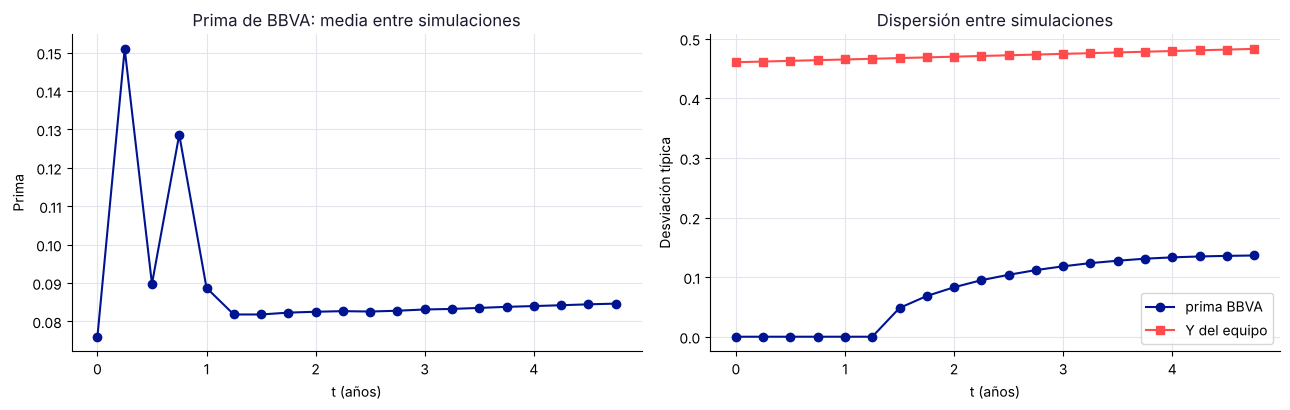

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))

ejes[0].plot(resumen["t_v (años)"], resumen["prima BBVA media"], "o-", color=COLORES["azul_principal"])
ejes[0].set_title("Prima de BBVA: media entre simulaciones", color=COLORES["gris_oscuro"])
ejes[0].set(xlabel="t (años)", ylabel="Prima")

ejes[1].plot(resumen["t_v (años)"], resumen["prima BBVA desv. típica"], "o-", color=COLORES["azul_principal"], label="prima BBVA")
ejes[1].plot(resumen["t_v (años)"], resumen["Y equipo desv. típica"], "s-", color=COLORES["acento"], label="Y del equipo")
ejes[1].set_title("Dispersión entre simulaciones", color=COLORES["gris_oscuro"])
ejes[1].set(xlabel="t (años)", ylabel="Desviación típica")
ejes[1].legend()

for ax in ejes:
    ax.grid(color=COLORES["gris_claro"])
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.show()

Los saltos de la prima media en los primeros instantes no son ruido: hasta $v = 5$ **todas las simulaciones comparten historia**, así que esa "media" es la prima de una única trayectoria (el comienzo común) y cambia a medida que se observan sus primeros trimestres.

La dispersión entre simulaciones es **cero hasta $v = 5$** (comienzo común) y crece después, porque a medida que se observan más trimestres la prima de cada simulación se va separando de las demás.

## 8. Guardar el resultado

In [12]:
np.savez("Datos/prima_bbva.npz", prima_bbva=prima_bbva.astype(np.float32), Y_equipo=Y_equipo.astype(np.float32))
print("Guardado en Datos/prima_bbva.npz:", prima_bbva.shape)

Guardado en Datos/prima_bbva.npz: (100000, 20)


## 9. Conclusiones

- `prima_bbva` tiene una prima para **cada simulación y cada instante** $v = 0, \dots, 19$, calculada solo con los $v$ primeros trimestres de esa simulación.
- La implementación coincide con la función original de BBVA y con un Montecarlo de su propio pago, así que está bien aplicada.
- Es la referencia de BBVA que se usará en la comparación con la RNN. Como valora otro pago, no es un objetivo que la red deba reproducir, sino una referencia para ver cómo se comporta la prima.